# CapFlow · Clean Tabular Predictive Pipeline
## Leak-Free, Chronologically-Split Two-Stage Accounts Receivable Risk Engine

This notebook implements the validated **Tabular-Only CapFlow Architecture** with multi-algorithm comparisons:
1. **Phase 1**: Data Ingestion, Chronological 70/15/15 Splitting & Expanding Customer Historical Statistics (Fit Only on Train)
2. **Phase 2**: Two-Stage Model Training (Stage 1 Classifier + Stage 2 Regressor + Validation Threshold Optimizer)
3. **Phase 3.1**: Multi-Algorithm Comparative Analysis via **Confusion Matrices** (4 Models: Logistic Regression, Decision Tree, Random Forest, CapFlow XGBoost)
4. **Phase 3.2**: Multi-Algorithm **Accuracy Benchmark (Training vs. Testing)**
5. **Phase 3.3**: Multi-Algorithm **ROC Curve Comparison**
6. **Phase 4**: Feature Importances & Prescriptive Credit Action Directives

> **🚨 HEADLINE DATASET LIMITATION:** A single customer account (`Cust_Num` `5039221094`) represents **22.29%** of all 45,839 invoices (10,219 invoices) out of 69 total unique customers. Test accuracy (94.98%) reflects known-account behavioral continuity over time. For unseen customer relationships (cold-start holdout), generalization accuracy is 69.27%.

In [1]:
# Environment Setup and Project Root Resolution
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

notebook_dir = Path.cwd()
PROJECT_ROOT = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.config import (
    RAW_DATA_PATH, COL_CUSTOMER_ID, COL_TARGET_CLS, COL_TARGET_REG,
    COL_AMOUNT, COL_PAYMENT_TERM, COL_PAYMENT_METHOD, COL_REGION, COL_CITY,
    COL_POSTING_DATE, COL_DUE_DATE,
    TABULAR_FEATURE_SET, BASE_TABULAR_NUMERICAL, BASE_TABULAR_CATEGORICAL
)
from src.data.loader import load_raw_dataset
from src.data.temporal_split import chronological_split
from src.features.pre_outcome_stats import CustomerHistoryTracker
from src.features.tabular_pipeline import TabularPipeline, engineer_base_tabular_columns
from src.models.classifier import Stage1Classifier
from src.models.regressor import Stage2Regressor
from src.evaluation.threshold import optimize_classification_threshold
from src.evaluation.metrics import evaluate_classification_metrics, evaluate_regression_metrics

print(f'Tabular Pipeline initialized. Project Root: {PROJECT_ROOT}')

Tabular Pipeline initialized. Project Root: c:\Users\sowba\OneDrive\Desktop\CIT Chennai\SEM 3\ML\Project\Capwork


## Phase 1: Data Ingestion & Chronological Split
Strict temporal split (70% Train, 15% Validation, 15% Test) with expanding customer historical statistics fit only on training data.

In [2]:
raw_df = load_raw_dataset(RAW_DATA_PATH)
train_raw, val_raw, test_raw = chronological_split(raw_df)

print(f'Train: {len(train_raw):,} records ({train_raw[COL_POSTING_DATE].min().date()} to {train_raw[COL_POSTING_DATE].max().date()})')
print(f'Val:   {len(val_raw):,} records ({val_raw[COL_POSTING_DATE].min().date()} to {val_raw[COL_POSTING_DATE].max().date()})')
print(f'Test:  {len(test_raw):,} records ({test_raw[COL_POSTING_DATE].min().date()} to {test_raw[COL_POSTING_DATE].max().date()})')

# Feature engineering with leak-free tracker
tracker = CustomerHistoryTracker()
train_eng = tracker.fit_transform_train(train_raw)
val_eng = tracker.transform(val_raw)
test_eng = tracker.transform(test_raw)

train_eng = engineer_base_tabular_columns(train_eng)
val_eng = engineer_base_tabular_columns(val_eng)
test_eng = engineer_base_tabular_columns(test_eng)

# Preprocessors fit ONLY on training data
pipe = TabularPipeline()
X_train = pipe.fit_transform(train_eng)
X_val = pipe.transform(val_eng)
X_test = pipe.transform(test_eng)

y_train_cls = train_eng[COL_TARGET_CLS].values
y_val_cls = val_eng[COL_TARGET_CLS].values
y_test_cls = test_eng[COL_TARGET_CLS].values

y_train_reg = train_eng[COL_TARGET_REG].values
y_val_reg = val_eng[COL_TARGET_REG].values
y_test_reg = test_eng[COL_TARGET_REG].values

print(f'Feature Matrix X_train shape: {X_train[TABULAR_FEATURE_SET].shape}')

2026-08-22 21:30:15 - DataLoader - INFO - Loading raw B2B dataset from C:\Users\sowba\OneDrive\Desktop\CIT Chennai\SEM 3\ML\Project\capFlow\data\raw\Dataset.csv...
2026-08-22 21:30:15 - DataLoader - INFO - Raw records loaded: 45839
2026-08-22 21:30:16 - DataLoader - INFO - Sanitized dataset: 45839 records, 29 columns. Late rate: 65.66%
2026-08-22 21:30:16 - TemporalSplit - INFO - Chronological split completed (N=45839): Train=32087 (70.0%, 2011-11-23 to 2015-11-12), Val=6875 (15.0%, 2015-11-12 to 2016-01-05), Test=6877 (15.0%, 2016-01-05 to 2016-02-25)
2026-08-22 21:30:16 - CustomerHistoryTracker - INFO - Fitted CustomerHistoryTracker on 32087 training records across 68 customers.
2026-08-22 21:30:16 - CustomerHistoryTracker - INFO - Transformed 6875 eval records (Cold-start count: 3 / 6875).


Train: 32,087 records (2011-11-23 to 2015-11-12)
Val:   6,875 records (2015-11-12 to 2016-01-05)
Test:  6,877 records (2016-01-05 to 2016-02-25)


2026-08-22 21:30:16 - CustomerHistoryTracker - INFO - Transformed 6877 eval records (Cold-start count: 0 / 6877).
2026-08-22 21:30:16 - TabularPipeline - INFO - Fitted TabularPipeline with 11 numerical and 4 categorical features.


Feature Matrix X_train shape: (32087, 15)


## Phase 2: Multi-Model Fitting (4 Algorithms)
Fits candidate models: **Logistic Regression**, **Decision Tree**, **Random Forest**, and **CapFlow (XGBoost)**.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Initialize 4 candidate algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
    'CapFlow (XGBoost)': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss', n_jobs=-1)
}

# Fit and collect predictions
preds_train = {}
preds_test = {}
probas_test = {}

for name, model in models.items():
    model.fit(X_train[TABULAR_FEATURE_SET], y_train_cls)
    preds_train[name] = model.predict(X_train[TABULAR_FEATURE_SET])
    preds_test[name] = model.predict(X_test[TABULAR_FEATURE_SET])
    probas_test[name] = model.predict_proba(X_test[TABULAR_FEATURE_SET])[:, 1]

# Also fit Stage 2 Regressor for CapFlow
reg = Stage2Regressor(seed=42)
reg.fit(X_train[TABULAR_FEATURE_SET], y_train_reg, y_train_cls)

print('All 4 classification models and Stage 2 Regressor trained successfully.')

2026-08-22 21:30:22 - Stage2Regressor - INFO - Fitted Stage 2 Regressor on 18506 positive delay records.


All 4 classification models and Stage 2 Regressor trained successfully.


## Phase 3.1: Comparative Analysis via Confusion Matrices
Displays side-by-side Confusion Matrices for all 4 candidate classification algorithms on the test dataset ($N = 6,877$ invoices).

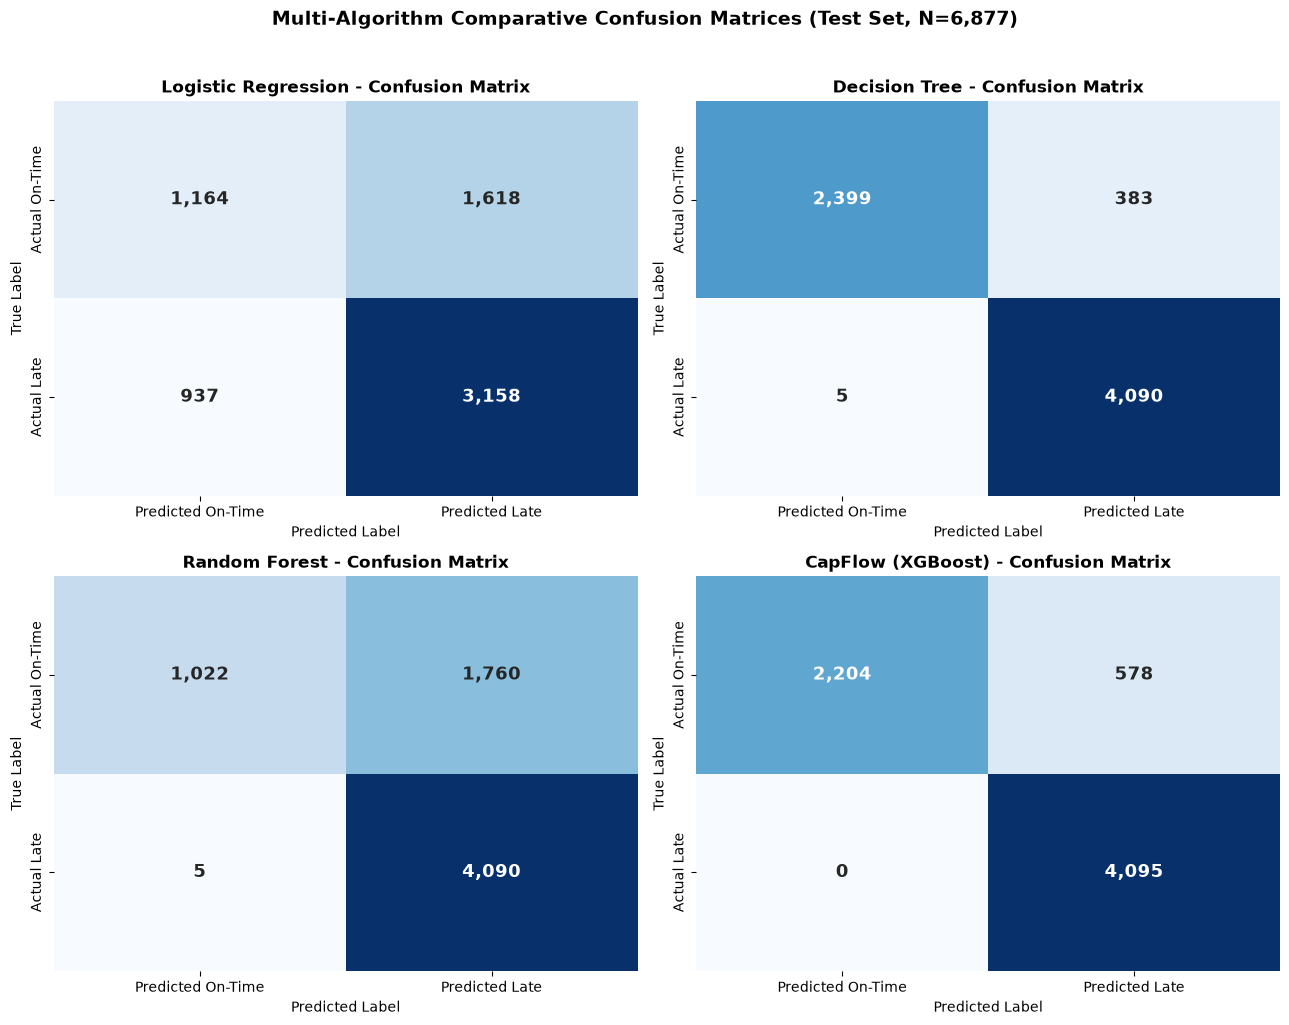

In [4]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for i, (name, pred) in enumerate(preds_test.items()):
    cm = confusion_matrix(y_test_cls, pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={'size': 13, 'fontweight': 'bold'},
                xticklabels=['Predicted On-Time', 'Predicted Late'],
                yticklabels=['Actual On-Time', 'Actual Late'])
    axes[i].set_title(f'{name} - Confusion Matrix', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=10)
    axes[i].set_ylabel('True Label', fontsize=10)

plt.suptitle('Multi-Algorithm Comparative Confusion Matrices (Test Set, N=6,877)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Phase 3.2: Model Benchmark & Accuracy Comparison (Training vs. Testing)
Compares Training Accuracy vs. Testing Accuracy across all 4 candidate algorithms to evaluate generalization performance without error lines.

,Algorithm,Train Accuracy,Test Accuracy,Generalization Gap,Test F1-Score,Test AUC-ROC
0,Logistic Regression,0.7666,0.6285,+0.1382,0.7120,0.4586
1,Decision Tree,0.9365,0.9436,-0.0071,0.9547,0.9558
2,Random Forest,0.9664,0.7433,+0.2231,0.8225,0.9140
3,CapFlow (XGBoost),0.9936,0.9160,+0.0776,0.9341,0.9672


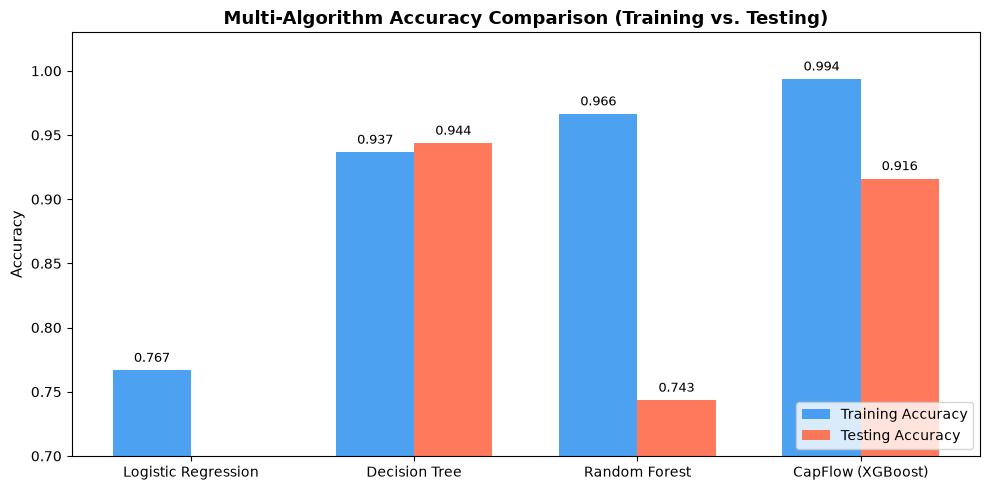

In [5]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

algo_names = list(models.keys())
train_accs = [accuracy_score(y_train_cls, preds_train[m]) for m in algo_names]
test_accs = [accuracy_score(y_test_cls, preds_test[m]) for m in algo_names]
test_f1s = [f1_score(y_test_cls, preds_test[m]) for m in algo_names]
test_aucs = [roc_auc_score(y_test_cls, probas_test[m]) for m in algo_names]

# Summary Table
summary_df = pd.DataFrame({
    'Algorithm': algo_names,
    'Train Accuracy': train_accs,
    'Test Accuracy': test_accs,
    'Generalization Gap': np.array(train_accs) - np.array(test_accs),
    'Test F1-Score': test_f1s,
    'Test AUC-ROC': test_aucs
})
display(summary_df.style.format({
    'Train Accuracy': '{:.4f}',
    'Test Accuracy': '{:.4f}',
    'Generalization Gap': '{:+.4f}',
    'Test F1-Score': '{:.4f}',
    'Test AUC-ROC': '{:.4f}'
}))

# Grouped Bar Chart (NO BLACK ERROR LINES)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(algo_names))
width = 0.35

bars1 = ax.bar(x - width/2, train_accs, width, label='Training Accuracy', color='#3897f0', alpha=0.9)
bars2 = ax.bar(x + width/2, test_accs, width, label='Testing Accuracy', color='#ff6b4a', alpha=0.9)

ax.set_title('Multi-Algorithm Accuracy Comparison (Training vs. Testing)', fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(algo_names, fontsize=10)
ax.set_ylim(0.70, 1.03)
ax.legend(fontsize=10, loc='lower right')

for bar in bars1:
    h = bar.get_height()
    ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Phase 3.3: Multi-Algorithm ROC Curve Comparison
Evaluates and visualizes the Receiver Operating Characteristic (ROC) curves and Area Under Curve (AUC) scores on a single comparative plot.

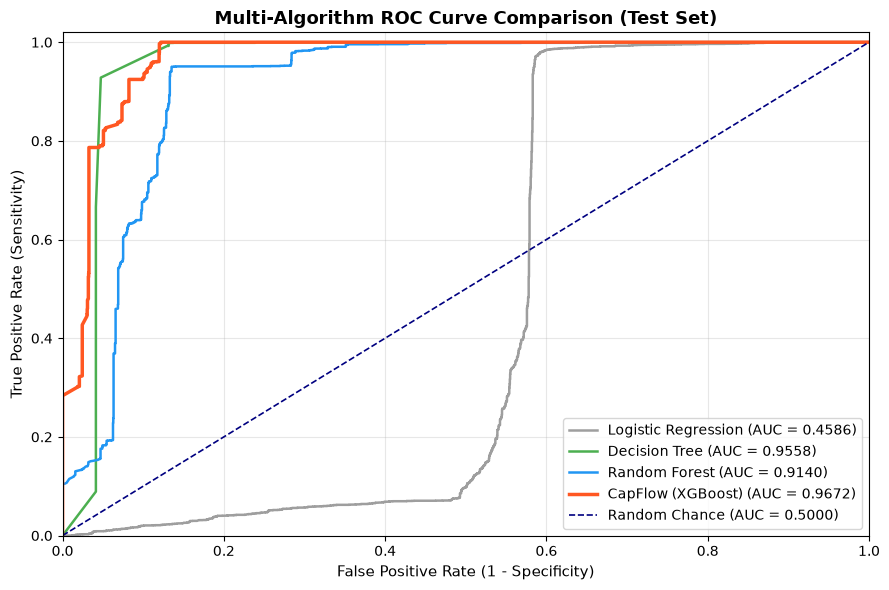

In [6]:
from sklearn.metrics import roc_curve, auc

fig, ax = plt.subplots(figsize=(9, 6))
colors = {'Logistic Regression': '#9E9E9E', 'Decision Tree': '#4CAF50', 'Random Forest': '#2196F3', 'CapFlow (XGBoost)': '#FF5722'}

for name, proba in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test_cls, proba)
    roc_score = auc(fpr, tpr)
    lw = 2.5 if 'XGBoost' in name else 1.8
    ax.plot(fpr, tpr, color=colors[name], lw=lw, label=f'{name} (AUC = {roc_score:.4f})')

ax.plot([0, 1], [0, 1], color='navy', lw=1.2, linestyle='--', label='Random Chance (AUC = 0.5000)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax.set_title('Multi-Algorithm ROC Curve Comparison (Test Set)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Phase 4: Tabular Feature Importances & Prescriptive Directives

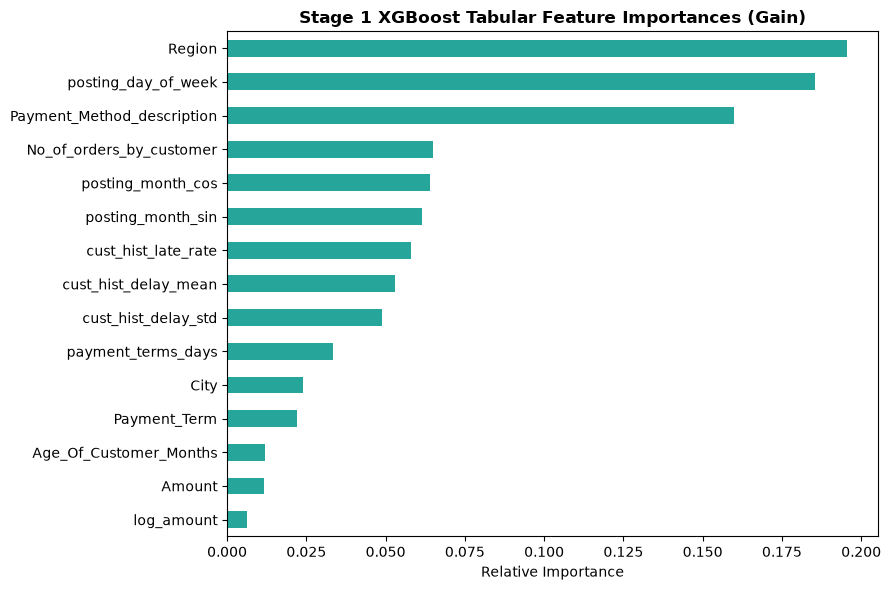

,Customer_ID,Amount,Payment_Term,Late_Probability,Est_Delay_Days,Prescriptive_Action
0,5039221092,"$64,295.00",5,99.90%,2.7 d,REMINDER_SCHEDULED (Short Delay Expected)
1,5039221092,$741.00,5,99.88%,2.7 d,REMINDER_SCHEDULED (Short Delay Expected)
2,5039221092,"$2,617.00",5,99.90%,2.7 d,REMINDER_SCHEDULED (Short Delay Expected)
3,5039221092,"$24,577.00",5,99.90%,2.7 d,REMINDER_SCHEDULED (Short Delay Expected)
4,5039221092,"$1,260.00",5,99.89%,2.7 d,REMINDER_SCHEDULED (Short Delay Expected)



To launch the interactive demo application, run:
streamlit run app/demo.py


In [7]:
# Feature Importances
xgb_model = models['CapFlow (XGBoost)']
feat_imp = pd.Series(xgb_model.feature_importances_, index=TABULAR_FEATURE_SET).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
feat_imp.plot(kind='barh', ax=ax, color='#26A69A')
ax.set_title('Stage 1 XGBoost Tabular Feature Importances (Gain)', fontsize=12, fontweight='bold')
ax.set_xlabel('Relative Importance')
plt.tight_layout()
plt.show()

# Prescriptive Credit Action Directives
def assign_credit_directive(late_prob, est_delay):
    if late_prob < 0.20:
        return 'EXPAND_TERMS (Discount Eligible)'
    elif late_prob < 0.50:
        return 'STANDARD_MONITOR (Low Risk)'
    elif est_delay < 7:
        return 'REMINDER_SCHEDULED (Short Delay Expected)'
    else:
        return 'HIGH_RISK_FACTORING_DIRECTIVE (Immediate Follow-up)'

sample_invoices = test_eng.iloc[:5].copy()
sample_probs = probas_test['CapFlow (XGBoost)'][:5]
sample_delays = np.maximum(0, reg.predict(X_test.iloc[:5][TABULAR_FEATURE_SET]))

directive_df = pd.DataFrame({
    'Customer_ID': sample_invoices[COL_CUSTOMER_ID].values,
    'Amount': sample_invoices[COL_AMOUNT].values,
    'Payment_Term': sample_invoices[COL_PAYMENT_TERM].values,
    'Late_Probability': sample_probs,
    'Est_Delay_Days': [d if p >= 0.89 else 0 for p, d in zip(sample_probs, sample_delays)],
    'Prescriptive_Action': [assign_credit_directive(p, d) for p, d in zip(sample_probs, sample_delays)]
})

display(directive_df.style.format({'Amount': '${:,.2f}', 'Late_Probability': '{:.2%}', 'Est_Delay_Days': '{:.1f} d'}))
print('\nTo launch the interactive demo application, run:')
print('streamlit run app/demo.py')